# Analysing MSE and MAE

## TASK 3
- plot the running avg absolute error for k = 1,3,5,9
- we choose the best performing `p` based on the tuning period, the `p` which minimises the MAE averaged over k in the tuning set

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent          # project folder (one level above notebooks/)
sys.path.insert(0, str(ROOT))
FIG = ROOT / "figures"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from outputs_io import load_results, load_predictions

res = load_results()
pred = load_predictions()
test = pred[pred["period"] == "test"].reset_index(drop=True)   # R_t(k) starts at the test period

best p: {'RLS': 5, 'CR-RLS': 6, 'AROWR': 8, 'ARCOR': 8, 'AAR': 8, 'LASER': 8}
0.5428675373568921 0.5428675373568902


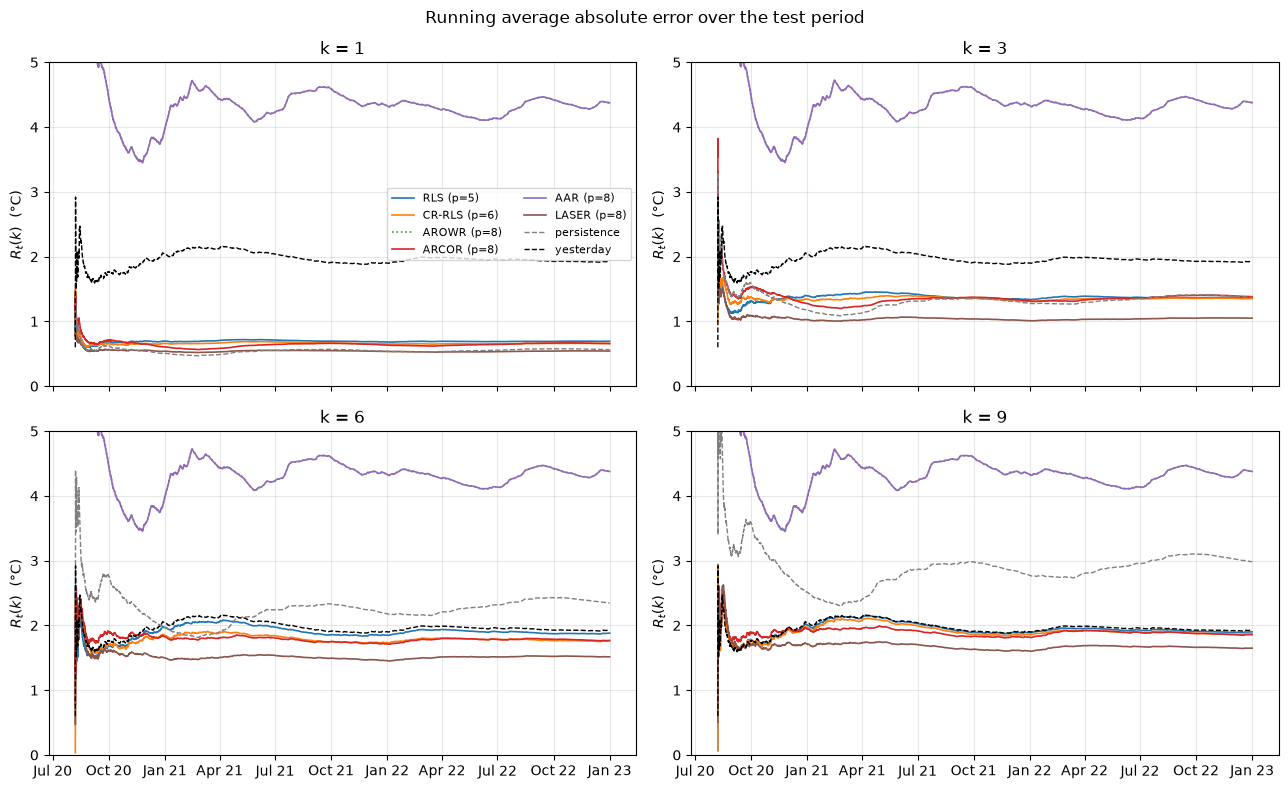

In [2]:
MODELS = ["RLS", "CR-RLS", "AROWR", "ARCOR", "AAR", "LASER"]
BASELINES = ["persistence", "yesterday"]
K_PLOT = [1, 3, 6, 9, 12]


def running_mae(obs, y_hat):
    """R_t(k) = (1/t) * sum_{s<=t} |y_s - y_hat_s|, skipping hours with no prediction."""
    e = np.abs(obs - y_hat)
    ok = ~np.isnan(e)
    total = np.cumsum(np.where(ok, e, 0.0))   # running sum of |errors|
    count = np.cumsum(ok)                     # number of errors so far
    return np.where(count > 0, total / np.maximum(count, 1), np.nan)

# best p per algorithm: lowest TUNING-period MAE averaged over k (no test data used)
tune = pred[pred["period"] == "tune"]
tune_mae = {(alg, p): np.mean([np.nanmean(np.abs(tune["obs"] - tune[f"{alg}_k{k}_p{p}"]))
                                for k in range(1, 13)])
            for alg in MODELS for p in range(3, 9)}
best_p = {alg: min(range(3, 9), key=lambda p: tune_mae[(alg, p)]) for alg in MODELS}
print("best p:", best_p)

fig, axes = plt.subplots(2, 2, figsize=(13, 8), sharex=True)
for ax, k in zip(axes.flat, K_PLOT):
    for alg in MODELS:
        col = f"{alg}_k{k}_p{best_p[alg]}"
        style = ":" if alg == "AROWR" else "-"        # AROWR = AAR exactly, so dot it to keep both visible
        ax.plot(test["time"], running_mae(test["obs"], test[col]), style,
                label=f"{alg} (p={best_p[alg]})", lw=1.2)
    for b in BASELINES:
        ax.plot(test["time"], running_mae(test["obs"], test[f"{b}_k{k}"]), "--",
                color="grey" if b == "persistence" else "black", label=b, lw=1)
    ax.set_title(f"k = {k}")
    ax.set_ylabel(r"$R_t(k)$  (°C)")
    ax.set_ylim(0, 5)
    ax.grid(alpha=0.3)
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %y"))
axes[0, 0].legend(fontsize=8, ncol=2)
fig.suptitle("Running average absolute error over the test period")
fig.tight_layout()
fig.savefig(FIG / "Rt_by_k.png", dpi=150, bbox_inches="tight")

# check: last value of R_t(k) should equal the MAE in results.csv
alg, k = "LASER", 1
row = res[(res["algorithm"] == alg) & (res["k"] == k) & (res["p"] == best_p[alg])]
print(running_mae(test["obs"], test[f"{alg}_k{k}_p{best_p[alg]}"])[-1], row["mae"].item())

[to do: try to zoom into the condensed lines]

## Task 4

/var/folders/q4/ssyyrh2j2qg2gn248xv9mw9h0000gn/T/ipykernel_58672/297095525.py:19: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  settled = test["time"] > test["time"].iloc[0] + pd.Timedelta(days=30)


p               3.0    4.0    5.0    6.0    7.0    8.0
algorithm k                                           
AAR       1   4.416  4.382  4.376  4.374  4.373  4.373
          3   4.417  4.384  4.378  4.376  4.376  4.376
          6   4.419  4.385  4.380  4.377  4.376  4.376
          9   4.419  4.385  4.379  4.376  4.376  4.376
          12  4.419  4.385  4.379  4.376  4.376  4.376
ARCOR     1   0.664  0.659  0.657  0.656  0.657  0.657
          3   1.438  1.383  1.377  1.378  1.380  1.382
          6   2.077  2.050  1.756  1.758  1.777  1.767
          9   2.163  2.117  1.833  2.147  1.862  1.858
          12  2.189  2.133  1.904  2.170  1.925  2.164
AROWR     1   4.416  4.382  4.376  4.374  4.373  4.373
          3   4.417  4.384  4.378  4.376  4.376  4.376
          6   4.419  4.385  4.380  4.377  4.376  4.376
          9   4.419  4.385  4.379  4.376  4.376  4.376
          12  4.419  4.385  4.379  4.376  4.376  4.376
CR-RLS    1   1.353  0.799  0.697  0.660  0.678  0.699
          3   1.846  1.487  1.373  1.352  1.354  1.360
          6   2.062  1.841  1.768  1.760  1.766  1.771
          9   2.073  1.922  1.888  1.869  1.862  1.867
          12  2.094  1.933  1.880  1.863  1.896  1.899
LASER     1   0.609  0.568  0.555  0.549  0.544  0.543
          3   1.411  1.155  1.085  1.055  1.049  1.050
          6   1.871  1.601  1.548  1.511  1.512  1.515
          9   1.911  1.720  1.653  1.651  1.649  1.649
          12  1.964  1.784  1.746  1.740  1.738  1.737
RLS       1   1.306  0.794  0.693  0.657  0.675  0.697
          3   1.895  1.479  1.370  1.377  1.490  1.595
          6   2.111  1.923  1.881  1.925  1.921  1.887
          9   2.135  1.968  1.901  1.869  1.862  1.867
          12  2.095  1.940  1.881  1.863  1.878  1.882

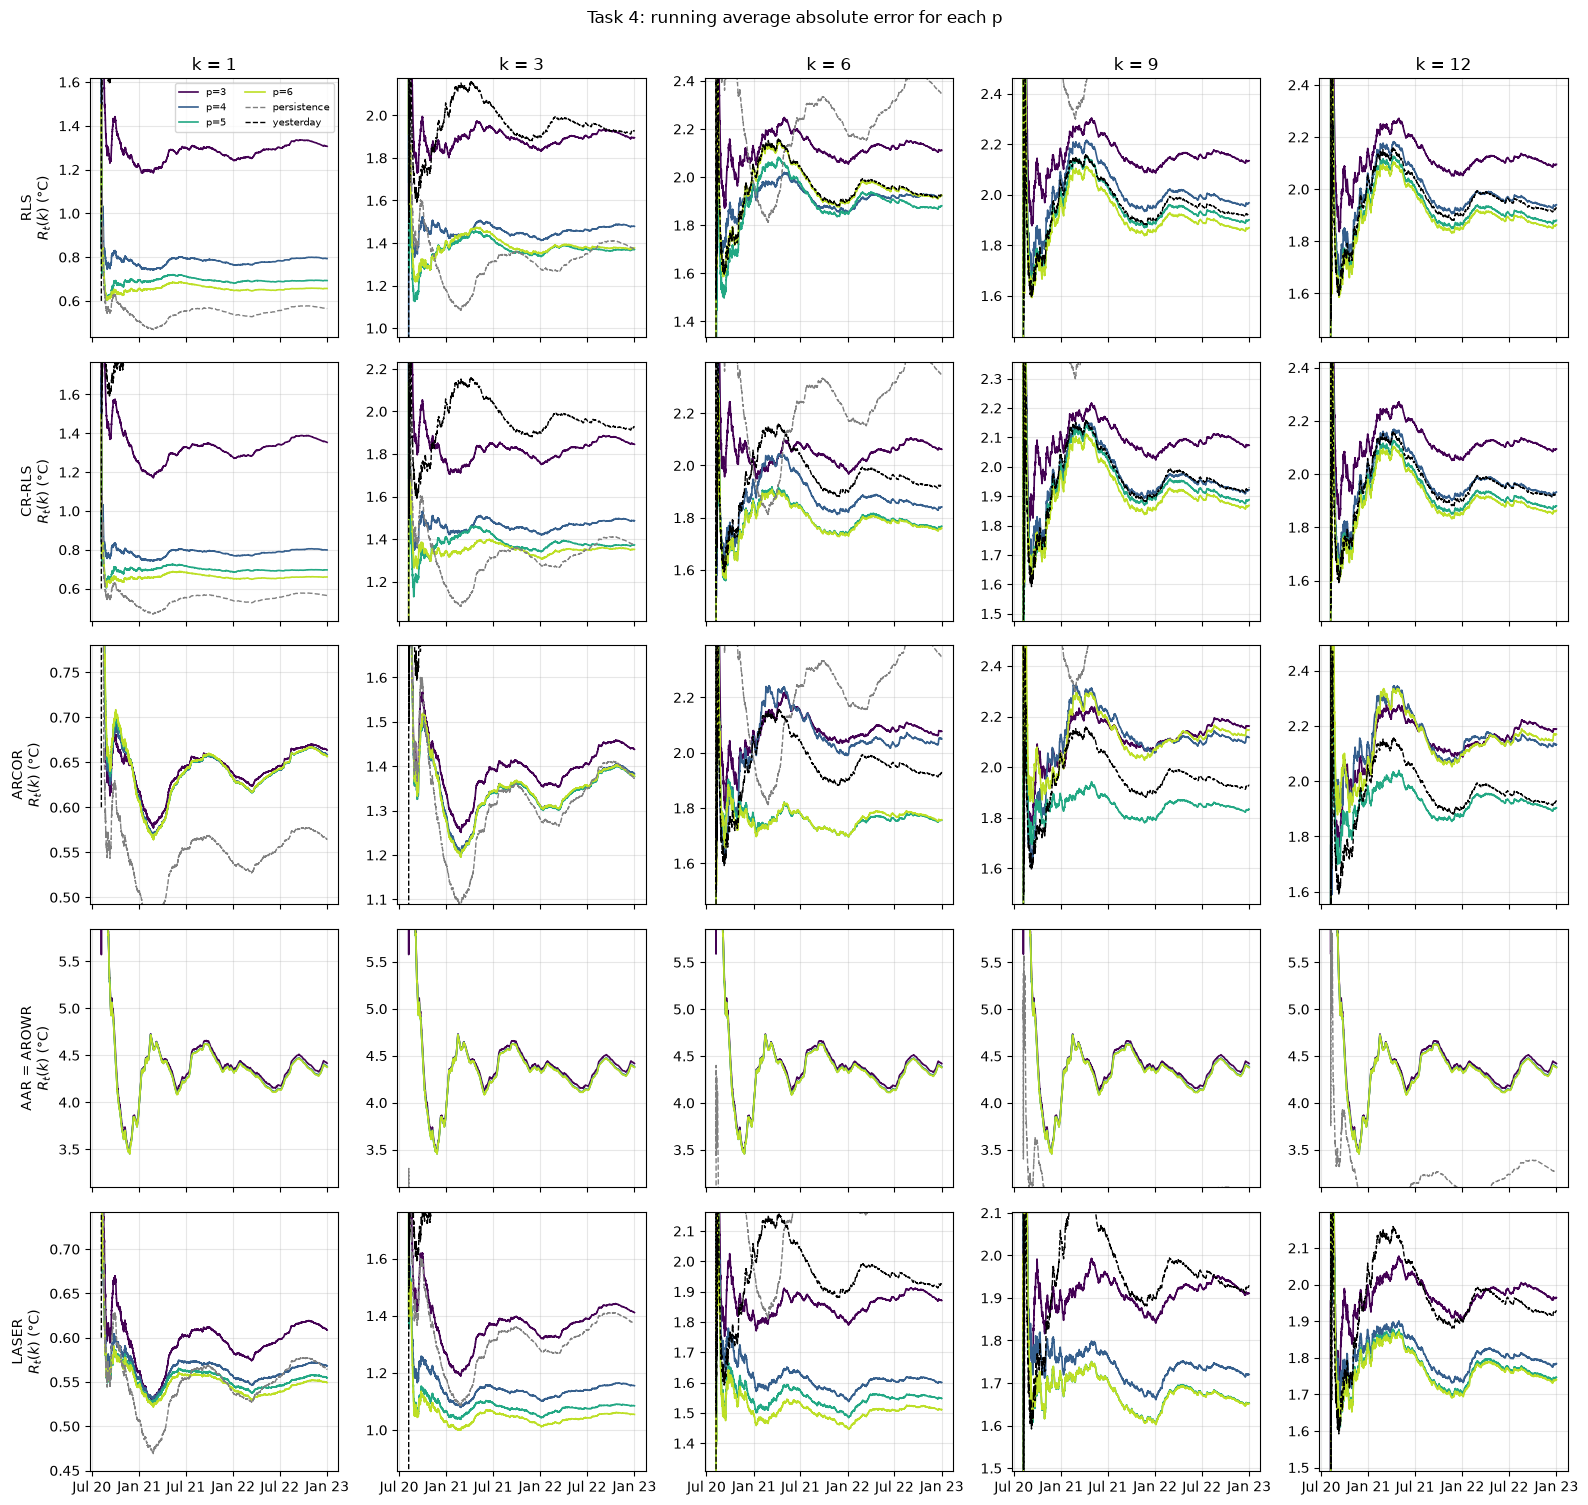

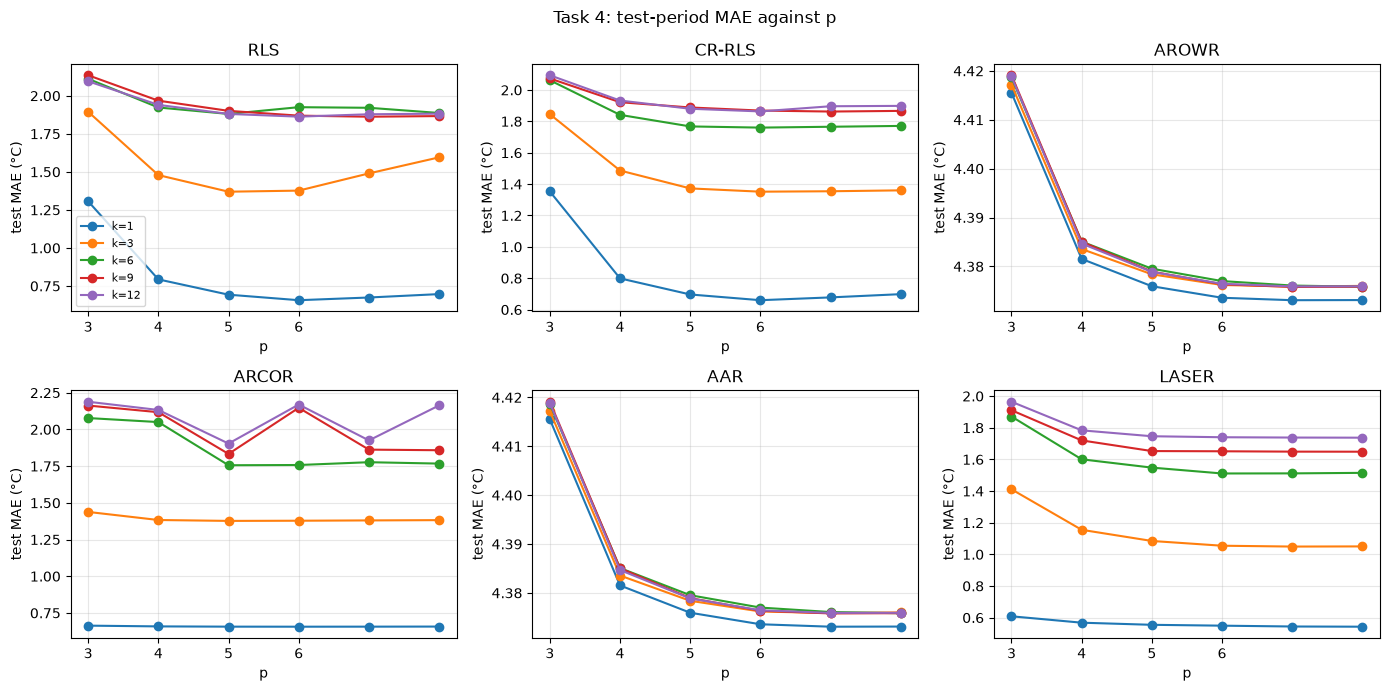

In [3]:
# ---------------------------------------------------------------- Task 4: repeat Task 3 for each p
P_LIST = [3, 4, 5, 6]
ROWS = [m for m in MODELS if m != "AROWR"]     # AROWR = AAR exactly, so one row covers both
colours = plt.cm.viridis(np.linspace(0, 0.9, len(P_LIST)))     # dark = few knots, light = many

fig, axes = plt.subplots(len(ROWS), len(K_PLOT), figsize=(16, 3 * len(ROWS)), sharex=True)
for i, alg in enumerate(ROWS):
    for j, k in enumerate(K_PLOT):
        ax = axes[i, j]
        for p, c in zip(P_LIST, colours):
            ax.plot(test["time"], running_mae(test["obs"], test[f"{alg}_k{k}_p{p}"]),
                    color=c, lw=1.2, label=f"p={p}")
        ax.plot(test["time"], running_mae(test["obs"], test[f"persistence_k{k}"]),
                "--", color="grey", lw=1, label="persistence")
        ax.plot(test["time"], running_mae(test["obs"], test[f"yesterday_k{k}"]),
                "--", color="black", lw=1, label="yesterday")

        # zoom the y-axis on this algorithm's own lines (ignore the noisy first month)
        settled = test["time"] > test["time"].iloc[0] + pd.Timedelta(days=30)
        vals = np.concatenate([running_mae(test["obs"], test[f"{alg}_k{k}_p{p}"])[settled] for p in P_LIST])
        lo, hi = np.nanmin(vals), np.nanmax(vals)
        pad = 0.15 * (hi - lo) + 0.05
        ax.set_ylim(lo - pad, hi + pad)

        ax.grid(alpha=0.3)
        ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 7]))
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %y"))
        if i == 0: ax.set_title(f"k = {k}")
        if j == 0: ax.set_ylabel(("AAR = AROWR" if alg == "AAR" else alg) + "\n" + r"$R_t(k)$ (°C)")
axes[0, 0].legend(fontsize=7, ncol=2)
fig.suptitle("Task 4: running average absolute error for each p", y=1.0)
fig.tight_layout()
fig.savefig(FIG / "Rt_by_p.png", dpi=150, bbox_inches="tight")

# ---------------------------------------------------------------- summary: final MAE (= R_T(k)) against p
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, alg in zip(axes.flat, MODELS):
    sub = res[res["algorithm"] == alg]
    for k in K_PLOT:
        d = sub[sub["k"] == k].sort_values("p")
        ax.plot(d["p"], d["mae"], "o-", label=f"k={k}")
    ax.set_title(alg)
    ax.set_xticks(P_LIST)
    ax.set_xlabel("p")
    ax.set_ylabel("test MAE (°C)")
    ax.grid(alpha=0.3)
axes[0, 0].legend(fontsize=8)
fig.suptitle("Task 4: test-period MAE against p")
fig.tight_layout()
fig.savefig(FIG / "mae_vs_p.png", dpi=150, bbox_inches="tight")

# table of final MAEs
res[res["algorithm"].isin(MODELS) & res["k"].isin(K_PLOT)] \
    .pivot_table(index=["algorithm", "k"], columns="p", values="mae").round(3)